files found in folder: 606
rows in CSV: 606
CSV rows with no file: 0
files not in CSV: 0

loaded: 406 | unreadable: 0
         images  patients
label                    
Scabies     406       114
manifest saved: eda_scabies/selected_manifest.csv


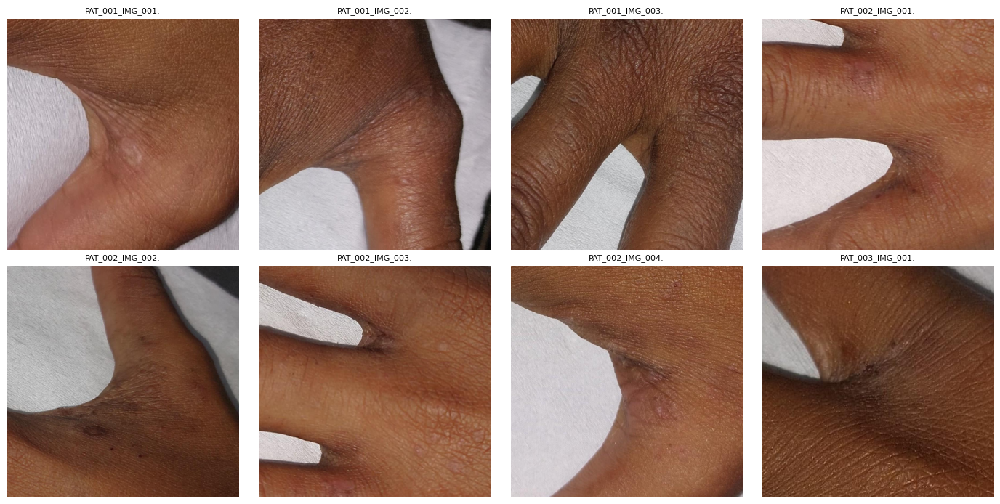

In [1]:
import os, glob, cv2, numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ---------- settings ----------
BASE = "/Users/macbook/Desktop/projects/A Benchmark Image Dataset for Scabies Detection_2."
ROOT = os.path.join(BASE, "SCAB_original")
CSV  = os.path.join(BASE, "SCAB_metadata_CSV.csv")
SIZE = (512, 512)
OUT = "eda_scabies"                              # ONE output folder for everything
FIG = os.path.join(OUT, "figures")              # every picture is saved here
os.makedirs(FIG, exist_ok=True)
RESIZE_MODE = "crop"   # "crop" = shorter side to 512 then centre-crop (no distortion) | "pad" = reflect-pad to square | "stretch" = your old behaviour (distorts)
MAX_UNMATCHED_PCT = 1  # stop if more than this % of CSV rows have no image file
USE_LABELS = ["Scabies"]        # all 406 scabies images; use ["Scabies", "Healthy"] for all 606

# ---------- check paths ----------
assert os.path.isdir(ROOT), f"Image folder not found: {ROOT}\nFolders in BASE: {os.listdir(BASE) if os.path.isdir(BASE) else 'BASE not found'}"
assert os.path.isfile(CSV), f"CSV not found: {CSV}\nFiles in BASE: {os.listdir(BASE) if os.path.isdir(BASE) else 'BASE not found'}"

# ---------- metadata ----------
meta = pd.read_csv(CSV)
meta = meta[meta["Image_id"].notna()].copy()
meta["Image_id"] = meta["Image_id"].astype(str).str.strip()
meta["patient"] = meta["Image_id"].str.extract(r"^(.+?)_IMG")[0]
meta["label"] = meta["Class Label"].str.strip()

# ---------- find image files (case-insensitive) ----------
exts = (".jpg", ".jpeg", ".png")
path_of = {os.path.basename(p).lower(): p
           for p in glob.glob(os.path.join(ROOT, "**", "*"), recursive=True)
           if p.lower().endswith(exts)}
meta["path"] = meta["Image_id"].str.lower().map(path_of)

print("files found in folder:", len(path_of))
print("rows in CSV:", len(meta))
print("CSV rows with no file:", meta["path"].isna().sum())
print("files not in CSV:", len(set(path_of) - set(meta["Image_id"].str.lower())))
if meta["path"].isna().any():
    print("example CSV names:", meta.loc[meta["path"].isna(), "Image_id"].head(3).tolist())
    print("example folder names:", list(path_of)[:3])

# ---------- stop if too many CSV rows have no image (instead of only printing a count) ----------
unmatched_pct = meta["path"].isna().mean() * 100
assert unmatched_pct <= MAX_UNMATCHED_PCT, (
    f"{unmatched_pct:.1f}% of CSV rows have no image file (limit {MAX_UNMATCHED_PCT}%). Fix names/paths before continuing.")

# ---------- aspect-ratio-safe resize (replaces the plain cv2.resize that stretched non-square photos) ----------
def resize_keep_aspect(img, size=SIZE, mode=RESIZE_MODE):
    h, w = img.shape[:2]; S = size[0]
    if mode == "stretch":
        return cv2.resize(img, size, interpolation=cv2.INTER_AREA)
    if mode == "crop":
        s = S / min(h, w)
        r = cv2.resize(img, (max(S, round(w * s)), max(S, round(h * s))), interpolation=cv2.INTER_AREA)
        y0, x0 = (r.shape[0] - S) // 2, (r.shape[1] - S) // 2
        return r[y0:y0 + S, x0:x0 + S]
    s = S / max(h, w)
    r = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    top, left = (S - r.shape[0]) // 2, (S - r.shape[1]) // 2
    return cv2.copyMakeBorder(r, top, S - r.shape[0] - top, left, S - r.shape[1] - left, cv2.BORDER_REFLECT_101)

# ---------- keep only the chosen classes ----------
sel_meta = meta[meta["path"].notna() & meta["label"].isin(USE_LABELS)].reset_index(drop=True)

# ---------- load the images ----------
selected, bad = {}, []
for r in sel_meta.itertuples():
    img = cv2.imread(r.path)
    if img is None:
        bad.append(r.Image_id)
        continue
    selected[r.Image_id] = resize_keep_aspect(img)
sel_meta = sel_meta[sel_meta["Image_id"].isin(selected)].reset_index(drop=True)

print("\nloaded:", len(selected), "| unreadable:", len(bad))
print(sel_meta.groupby("label").agg(images=("Image_id", "count"),
                                    patients=("patient", "nunique")))

sel_meta[["patient", "Image_id", "label", "Resolution", "resizedMin_512"]] \
    .to_csv(os.path.join(OUT, "selected_manifest.csv"), index=False)
print("manifest saved:", os.path.join(OUT, "selected_manifest.csv"))

# ---------- preview ----------
ids = list(selected)[:8]
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, i in zip(axes.ravel(), ids):
    ax.imshow(cv2.cvtColor(selected[i], cv2.COLOR_BGR2RGB))
    ax.set_title(i[:16], fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(FIG, "00_selected_preview.png"), dpi=200, bbox_inches="tight")
plt.show()

In [2]:
# ---------- method definitions (these were missing from the file: METHODS, get_L, stretch, ...) ----------
import numpy as np, cv2
NK = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)   # Immerkaer noise kernel

def get_L(img):
    return cv2.cvtColor(img, cv2.COLOR_BGR2LAB)[:, :, 0]

def metrics(L):
    f = L.astype(np.float32)
    H, W = f.shape
    p = np.bincount(L.ravel(), minlength=256) / L.size
    p = p[p > 0]
    gx, gy = cv2.Sobel(f, cv2.CV_32F, 1, 0), cv2.Sobel(f, cv2.CV_32F, 0, 1)
    conv = cv2.filter2D(f, -1, NK)[1:-1, 1:-1]
    sigma = np.sqrt(np.pi / 2) * np.abs(conv).sum() / (6 * (H - 2) * (W - 2))
    return dict(contrast=f.std(), entropy=-(p * np.log2(p)).sum(),
                edge=np.hypot(gx, gy).mean(), noise=sigma)

def stretch(L):
    lo, hi = np.percentile(L, (2, 98))
    return np.clip((L.astype(np.float32) - lo) / max(hi - lo, 1) * 255, 0, 255).astype(np.uint8)
def log_tf(L):
    c = 255 / np.log(256); return np.clip(c * np.log1p(L.astype(np.float32)), 0, 255).astype(np.uint8)
def gamma(L, g):
    return np.clip(255 * (L.astype(np.float32) / 255) ** g, 0, 255).astype(np.uint8)
def hist_eq(L): return cv2.equalizeHist(L)
def mean3(L): return cv2.blur(L, (3, 3))
def median3(L): return cv2.medianBlur(L, 3)
def laplacian_sharp(L):
    f = L.astype(np.float32); return np.clip(f - 0.5 * cv2.Laplacian(f, cv2.CV_32F), 0, 255).astype(np.uint8)
def unsharp(L, sigma=1.0, k=1.0):
    f = L.astype(np.float32); b = cv2.GaussianBlur(f, (0, 0), sigma); return np.clip(f + k * (f - b), 0, 255).astype(np.uint8)
def _edge(L, kx, ky):
    f = L.astype(np.float32)
    return np.clip(np.hypot(cv2.filter2D(f, -1, kx), cv2.filter2D(f, -1, ky)), 0, 255).astype(np.uint8)
def sobel(L):   return _edge(L, np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], np.float32), np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], np.float32))
def prewitt(L): return _edge(L, np.array([[-1, 0, 1]] * 3, np.float32), np.array([[-1] * 3, [0] * 3, [1] * 3], np.float32))
def roberts(L): return _edge(L, np.array([[1, 0], [0, -1]], np.float32), np.array([[0, 1], [-1, 0]], np.float32))

_L_FUNCS = {"stretch": stretch, "log": log_tf, "gamma_0.7": lambda L: gamma(L, 0.7), "gamma_1.5": lambda L: gamma(L, 1.5),
            "hist_eq": hist_eq, "mean_3x3": mean3, "median_3x3": median3, "laplacian": laplacian_sharp,
            "unsharp": lambda L: unsharp(L, 1.0, 1.0), "highboost_k2": lambda L: unsharp(L, 1.0, 2.0)}
_EDGE_FUNCS = {"sobel": sobel, "prewitt": prewitt, "roberts": roberts}

def _on_L(img, fn):
    lab = cv2.cvtColor(img, cv2.COLOR_BGR2LAB); lab[:, :, 0] = fn(lab[:, :, 0])
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR)
METHODS = {"original": lambda im: im, "negative": lambda im: 255 - im}
METHODS.update({m: (lambda im, fn=fn: _on_L(im, fn)) for m, fn in _L_FUNCS.items()})
METHODS.update({m: (lambda im, fn=fn: cv2.cvtColor(fn(get_L(im)), cv2.COLOR_GRAY2BGR)) for m, fn in _EDGE_FUNCS.items()})
print("methods ready:", list(METHODS))

methods ready: ['original', 'negative', 'stretch', 'log', 'gamma_0.7', 'gamma_1.5', 'hist_eq', 'mean_3x3', 'median_3x3', 'laplacian', 'unsharp', 'highboost_k2', 'sobel', 'prewitt', 'roberts']


# Part A: dataset EDA (all classes, original images)
Uses `meta` from the first cell. Covers class balance, patients, image size and aspect ratio, duplicates, photometric statistics by class, metadata, outliers and a leakage-safe split plan. Outputs go to `eda_scabies/`.

In [3]:
import re, hashlib, warnings
from PIL import Image
from scipy.stats import kruskal
warnings.filterwarnings("ignore")
os.makedirs(FIG, exist_ok=True)
SEED = 42; rng = np.random.default_rng(SEED); THUMB = 128

E = meta[meta["path"].notna()].reset_index(drop=True)          # every class with an image file (Scabies + Healthy)
E["patient"] = E["patient"].fillna(E["Image_id"].str.replace(r"\.[A-Za-z]+$", "", regex=True))
extra_cols = [c for c in meta.columns if c not in ("Image_id", "Class Label", "label", "patient", "path")]

recs, thumbs, bad = [], {}, []
for n, r in enumerate(E.itertuples()):
    img = cv2.imread(r.path)
    if img is None:
        bad.append(r.Image_id); continue
    h, w = img.shape[:2]
    with Image.open(r.path) as im:
        fmt, mode = im.format, im.mode
    L = get_L(img); m = metrics(L)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    with open(r.path, "rb") as fh:
        md5 = hashlib.md5(fh.read()).hexdigest()
    g9 = cv2.resize(cv2.cvtColor(img, cv2.COLOR_BGR2GRAY), (9, 8), interpolation=cv2.INTER_AREA)
    dh = int("".join("1" if b else "0" for b in (g9[:, 1:] > g9[:, :-1]).ravel()), 2)
    recs.append(dict(Image_id=r.Image_id, width=w, height=h, aspect=w / h, format=fmt, mode=mode,
        file_kb=os.path.getsize(r.path) / 1024, md5=md5, dhash=dh,
        mean_L=L.mean(), contrast=m["contrast"], entropy=m["entropy"],
        sharpness=cv2.Laplacian(L, cv2.CV_64F).var(), edge=m["edge"], noise=m["noise"],
        R=img[:, :, 2].mean(), G=img[:, :, 1].mean(), B=img[:, :, 0].mean(),
        sat=hsv[:, :, 1].mean(), val=hsv[:, :, 2].mean(),
        dark_pct=(L < 20).mean() * 100, bright_pct=(L > 235).mean() * 100))
    thumbs[r.Image_id] = cv2.resize(img, (THUMB, THUMB), interpolation=cv2.INTER_AREA)
    if (n + 1) % 200 == 0: print("processed", n + 1, "of", len(E))

stats_df = pd.DataFrame(recs)
D = E.merge(stats_df, on="Image_id", how="inner")
D.drop(columns=["dhash"]).to_csv(os.path.join(OUT, "image_table.csv"), index=False)
print("readable:", len(D), "| unreadable:", len(bad), bad[:5])
display(D[["Image_id", "label", "patient", "width", "height", "file_kb", "mean_L", "contrast", "sharpness"]].head())

processed 200 of 606
processed 400 of 606
processed 600 of 606
readable: 606 | unreadable: 0 []


,Image_id,label,patient,width,height,file_kb,mean_L,contrast,sharpness
0,PAT_001_IMG_001.jpg,Scabies,PAT_001,763,736,64.134766,118.861814,38.731586,82.040055
1,PAT_001_IMG_002.jpg,Scabies,PAT_001,1040,1209,150.307617,114.391566,56.321117,128.389945
2,PAT_001_IMG_003.jpg,Scabies,PAT_001,922,1045,155.699219,96.594800,45.801487,301.856214
3,PAT_002_IMG_001.jpg,Scabies,PAT_002,849,1031,77.908203,128.899888,43.453865,39.268163
4,PAT_002_IMG_002.jpg,Scabies,PAT_002,1411,1007,145.186523,110.495006,53.524288,89.912918


,images,patients,share_%,imgs_per_patient
label,,,,
Scabies,406,114,67.0,3.56
Healthy,200,55,33.0,3.64


Imbalance ratio (largest / smallest class): 2.03
Images per patient: mean 3.59, median 3, min 1, max 9
Patients appearing in more than one class: 0


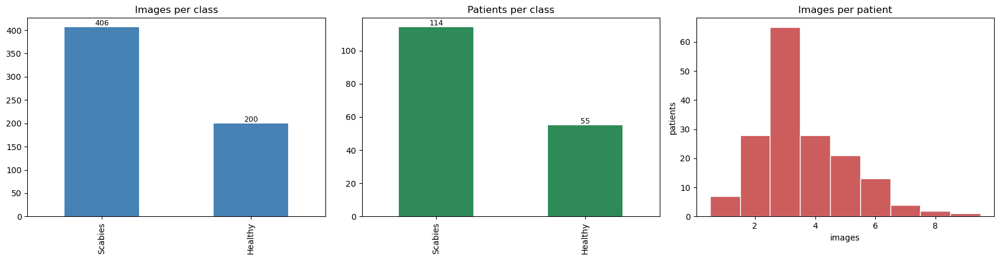


Actual resolutions (width x height):


images
width height        
512   512         12
      709          3
      596          3
      593          3
      517          3
      575          2
      737          2
      739          2
      745          2
      591          2

Non-square images: 97.5%  | aspect ratio min 0.365, max 2.923
Formats: {'JPEG': 606} | colour modes: {'RGB': 606}
File size (KB): mean 167.7, min 17.8, max 969.8

Resolution column in the CSV (first values): {'763x736': 1, '674x749': 1, '1852x966': 1, '1396x556': 1, '429x540': 1}


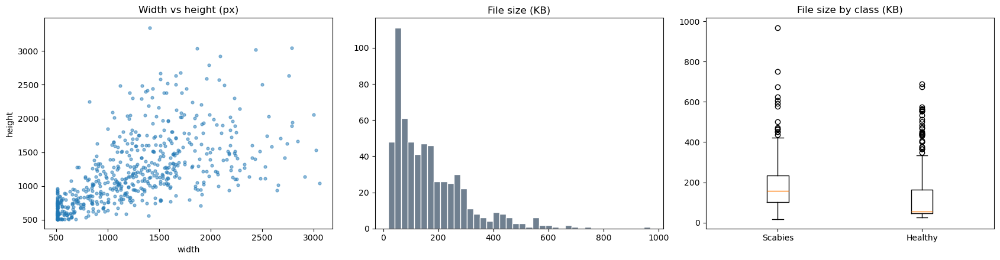

In [4]:
# ---------- class balance and patients ----------
cls = D.groupby("label").agg(images=("Image_id", "count"), patients=("patient", "nunique")).sort_values("images", ascending=False)
cls["share_%"] = (cls.images / cls.images.sum() * 100).round(1)
cls["imgs_per_patient"] = (cls.images / cls.patients).round(2)
display(cls)
print(f"Imbalance ratio (largest / smallest class): {cls.images.max() / cls.images.min():.2f}")
order = list(cls.index)

ipp = D.groupby("patient").size()
print(f"Images per patient: mean {ipp.mean():.2f}, median {ipp.median():.0f}, min {ipp.min()}, max {ipp.max()}")
multi = D.groupby("patient").label.nunique()
print("Patients appearing in more than one class:", int((multi > 1).sum()))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
cls.images.plot.bar(ax=ax[0], color="steelblue"); ax[0].set_title("Images per class"); ax[0].set_xlabel("")
for i, v in enumerate(cls.images): ax[0].text(i, v, str(v), ha="center", va="bottom", fontsize=9)
cls.patients.plot.bar(ax=ax[1], color="seagreen"); ax[1].set_title("Patients per class"); ax[1].set_xlabel("")
for i, v in enumerate(cls.patients): ax[1].text(i, v, str(v), ha="center", va="bottom", fontsize=9)
ax[2].hist(ipp, bins=range(1, int(ipp.max()) + 2), color="indianred", edgecolor="white", align="left")
ax[2].set_title("Images per patient"); ax[2].set_xlabel("images"); ax[2].set_ylabel("patients")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "01_class_patient_balance.png"), dpi=200, bbox_inches="tight"); plt.show()
cls.to_csv(os.path.join(OUT, "class_summary.csv"))

# ---------- image size, aspect ratio, format (this decides whether resizing distorts the images) ----------
print("\nActual resolutions (width x height):")
display(D.groupby(["width", "height"]).size().sort_values(ascending=False).rename("images").head(10).to_frame())
non_sq = (D.width != D.height).mean() * 100
print(f"Non-square images: {non_sq:.1f}%  | aspect ratio min {D.aspect.min():.3f}, max {D.aspect.max():.3f}")
print("Formats:", D.format.value_counts().to_dict(), "| colour modes:", D["mode"].value_counts().to_dict())
print(f"File size (KB): mean {D.file_kb.mean():.1f}, min {D.file_kb.min():.1f}, max {D.file_kb.max():.1f}")
if "Resolution" in D.columns:
    print("\nResolution column in the CSV (first values):", D["Resolution"].astype(str).value_counts().head(5).to_dict())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
ax[0].scatter(D.width, D.height, s=12, alpha=0.5); ax[0].set_title("Width vs height (px)"); ax[0].set_xlabel("width"); ax[0].set_ylabel("height")
ax[1].hist(D.file_kb, bins=40, color="slategray", edgecolor="white"); ax[1].set_title("File size (KB)")
ax[2].boxplot([D.loc[D.label == c, "file_kb"] for c in order], labels=order); ax[2].set_title("File size by class (KB)")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "02_image_properties.png"), dpi=200, bbox_inches="tight"); plt.show()

Exact duplicate files: 0 images in 0 groups

Near-duplicate pairs (dHash distance <= 4 of 64): 0


mean_L          contrast       entropy       sharpness         noise  \
           mean    std       mean   std    mean   std      mean     std  mean   
label                                                                           
Healthy  128.06  19.40  39.610001  8.54    7.14  0.29    308.33  360.21  1.12   
Scabies  118.83  18.65  42.150002  9.15    6.70  0.31     97.03   80.24  0.64   

                  sat        dark_pct       bright_pct        
          std    mean    std     mean   std       mean   std  
label                                                         
Healthy  0.70   50.00  17.79     0.38  0.56       0.18  0.55  
Scabies  0.24  109.59  24.12     0.54  1.71       0.43  2.37

Kruskal-Wallis p-value across classes (p < 0.05: the classes differ on that statistic, so a CNN could shortcut on it):


,p_value,significant
mean_L,0.0000,True
contrast,0.0012,True
entropy,0.0000,True
sharpness,0.0000,True
noise,0.0000,True
sat,0.0000,True
dark_pct,0.0000,True
bright_pct,0.0000,True


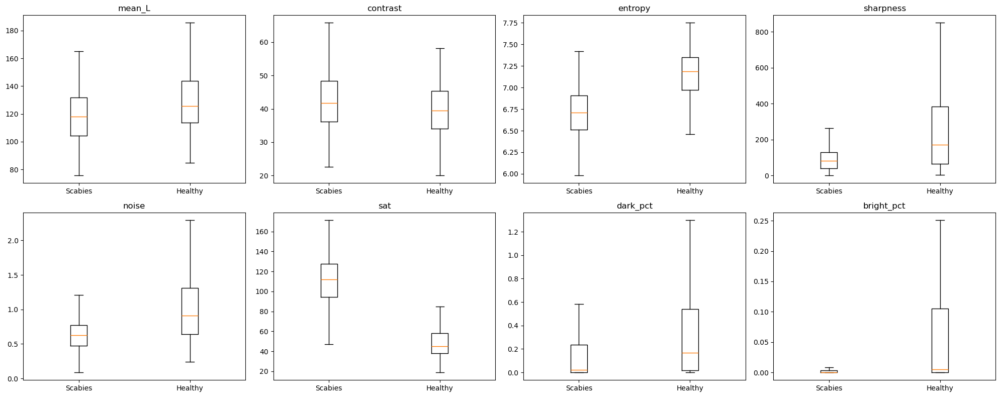

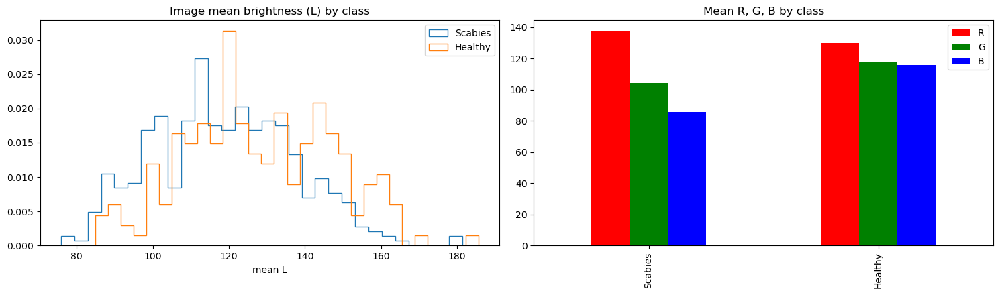

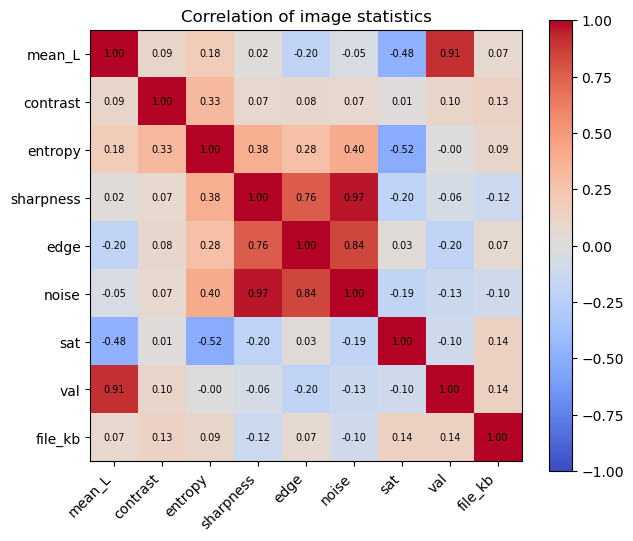

In [5]:
# ---------- duplicates and near-duplicates ----------
exact = D[D.duplicated("md5", keep=False)].sort_values("md5")
print("Exact duplicate files:", len(exact), "images in", exact.md5.nunique(), "groups")
if len(exact): display(exact[["md5", "Image_id", "label", "patient"]].head(15))

Hh = np.array([int(x) for x in D.dhash], dtype=np.uint64)
pairs = []
for i in range(len(Hh) - 1):
    x = np.bitwise_xor(Hh[i + 1:], Hh[i])
    dist = np.unpackbits(x.view(np.uint8).reshape(-1, 8), axis=1).sum(1)
    for j in np.where(dist <= 4)[0]:
        pairs.append((i, i + 1 + j, int(dist[j])))
nd = pd.DataFrame([dict(img_a=D.Image_id[a], img_b=D.Image_id[b], dist=d, patient_a=D.patient[a], patient_b=D.patient[b],
                        class_a=D.label[a], class_b=D.label[b]) for a, b, d in pairs])
print("\nNear-duplicate pairs (dHash distance <= 4 of 64):", len(nd))
if len(nd):
    nd["same_patient"] = nd.patient_a == nd.patient_b; nd["same_class"] = nd.class_a == nd.class_b
    print("  across different patients:", int((~nd.same_patient).sum()), "| across different classes (label conflict):", int((~nd.same_class).sum()))
    display(nd.sort_values("dist").head(15)); nd.to_csv(os.path.join(OUT, "near_duplicates.csv"), index=False)

# ---------- photometric statistics by class ----------
STATS = ["mean_L", "contrast", "entropy", "sharpness", "noise", "sat", "dark_pct", "bright_pct"]
summ = D.groupby("label")[STATS].agg(["mean", "std"]).round(2); display(summ)
summ.to_csv(os.path.join(OUT, "photometric_by_class.csv"))
kw = {s: kruskal(*[g[s].values for _, g in D.groupby("label")]).pvalue for s in STATS}
print("Kruskal-Wallis p-value across classes (p < 0.05: the classes differ on that statistic, so a CNN could shortcut on it):")
display(pd.Series(kw, name="p_value").to_frame().assign(significant=lambda t: t.p_value < 0.05).round(4))

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for ax, s in zip(axes.ravel(), STATS):
    ax.boxplot([D.loc[D.label == c, s] for c in order], labels=order, showfliers=False); ax.set_title(s)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "03_photometric_by_class.png"), dpi=200, bbox_inches="tight"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for c in order: ax[0].hist(D.loc[D.label == c, "mean_L"], bins=30, histtype="step", density=True, label=c)
ax[0].set_title("Image mean brightness (L) by class"); ax[0].set_xlabel("mean L"); ax[0].legend()
D.groupby("label")[["R", "G", "B"]].mean().loc[order].plot.bar(ax=ax[1], color=["red", "green", "blue"]); ax[1].set_title("Mean R, G, B by class"); ax[1].set_xlabel("")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "04_brightness_colour.png"), dpi=200, bbox_inches="tight"); plt.show()

corr = D[["mean_L", "contrast", "entropy", "sharpness", "edge", "noise", "sat", "val", "file_kb"]].corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5)); im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr))); ax.set_xticklabels(corr.columns, rotation=45, ha="right"); ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)): ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); ax.set_title("Correlation of image statistics")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "05_correlation.png"), dpi=200, bbox_inches="tight"); plt.show()

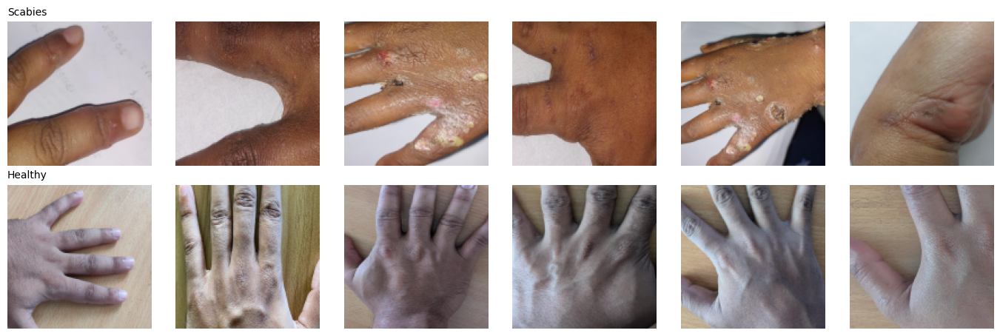

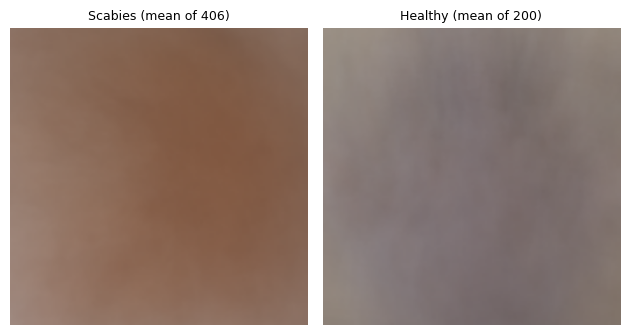


===== Environmental setting | missing: 0 (0.0%) | unique: 3 =====


label,Scabies,Healthy
Environmental setting,,
classroom,0,188
hospital_indoor,406,0
hospital_outdoor,0,12



===== Acquisition_type | missing: 0 (0.0%) | unique: 1 =====


label,Scabies,Healthy
Acquisition_type,,
2D,406,200



Images beyond 4 robust-SD of their own class median on any statistic: 86 (14.2%)


,Image_id,label,mean_L,contrast,sharpness,noise,file_kb,outlier_score
433,PAT_210_IMG_002.jpg,Healthy,134.14,41.930000,69.10,0.71,689.55,26.53
406,PAT_201_IMG_001.jpg,Healthy,121.47,27.010000,319.57,1.11,675.08,25.93
489,PAT_227_IMG_003.jpg,Healthy,100.27,38.070000,232.80,1.05,574.52,21.72
602,PAT_254_IMG_003.jpg,Healthy,112.81,34.099998,190.21,0.96,564.48,21.30
487,PAT_227_IMG_001.jpg,Healthy,108.60,44.750000,185.39,0.96,563.41,21.25
408,PAT_201_IMG_003.jpg,Healthy,111.42,35.000000,631.46,1.85,558.78,21.06
555,PAT_243_IMG_003.jpg,Healthy,159.54,39.070000,52.36,0.63,555.33,20.92
417,PAT_204_IMG_003.jpg,Healthy,124.25,36.830002,437.82,1.37,553.65,20.85
457,PAT_218_IMG_002.jpg,Healthy,162.23,47.509998,54.53,0.60,552.84,20.81
490,PAT_228_IMG_001.jpg,Healthy,110.54,37.669998,117.52,0.84,533.00,19.98


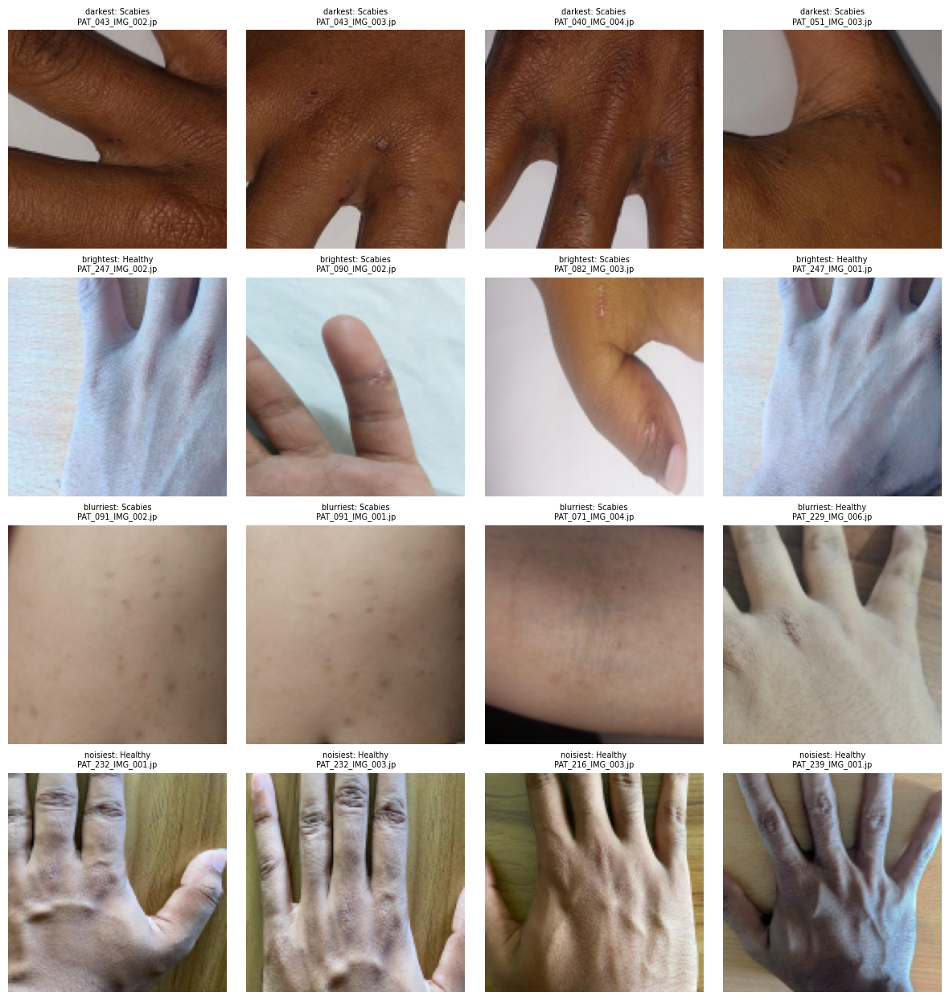

In [6]:
# ---------- samples and mean image per class ----------
K = 6
fig, axes = plt.subplots(len(order), K, figsize=(2.3 * K, 2.3 * len(order))); axes = np.atleast_2d(axes)
for r_, c in enumerate(order):
    ids = D.loc[D.label == c, "Image_id"].tolist(); pick = rng.choice(ids, size=min(K, len(ids)), replace=False)
    for k in range(K):
        a = axes[r_, k]; a.axis("off")
        if k < len(pick): a.imshow(cv2.cvtColor(thumbs[pick[k]], cv2.COLOR_BGR2RGB))
        if k == 0: a.set_title(c, fontsize=10, loc="left")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "06_samples_per_class.png"), dpi=200, bbox_inches="tight"); plt.show()

fig, axes = plt.subplots(1, len(order), figsize=(3.2 * len(order), 3.4)); axes = np.atleast_1d(axes)
for a, c in zip(axes, order):
    ids = D.loc[D.label == c, "Image_id"]
    a.imshow(cv2.cvtColor(np.mean([thumbs[i] for i in ids], axis=0).astype(np.uint8), cv2.COLOR_BGR2RGB))
    a.set_title(f"{c} (mean of {len(ids)})", fontsize=9); a.axis("off")
plt.tight_layout(); plt.savefig(os.path.join(FIG, "07_mean_image_per_class.png"), dpi=200, bbox_inches="tight"); plt.show()

# ---------- metadata columns ----------
mcols = [c for c in extra_cols if c in D.columns and c not in set(stats_df.columns)]
mcols = [c for c in mcols if not c.startswith("Unnamed") and c not in ("Object_id", "Resolution", "resizedMin_512")]   # notes/ID columns, not real metadata
for c in mcols:
    s = D[c]
    print(f"\n===== {c} | missing: {s.isna().sum()} ({s.isna().mean() * 100:.1f}%) | unique: {s.nunique()} =====")
    if pd.api.types.is_numeric_dtype(s) and s.nunique() > 12:
        display(s.describe().round(2).to_frame().T)
        fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
        ax[0].hist(s.dropna(), bins=30, color="steelblue", edgecolor="white"); ax[0].set_title(c)
        ax[1].boxplot([D.loc[D.label == k, c].dropna() for k in order], labels=order); ax[1].set_title(f"{c} by class")
        plt.tight_layout(); plt.savefig(os.path.join(FIG, f"meta_{re.sub(r'[^A-Za-z0-9]+', '_', c)}.png"), dpi=200, bbox_inches="tight"); plt.show()
    elif s.nunique() <= 25:
        ct = pd.crosstab(s.fillna("missing"), D.label)[order]; display(ct)
    else:
        print("high-cardinality column, first values:", s.dropna().astype(str).unique()[:5])

# ---------- outliers ----------
def robust_z(s):
    med = s.median(); mad = (s - med).abs().median() * 1.4826 + 1e-9
    return (s - med) / mad
Z = pd.DataFrame({s: D.groupby("label")[s].transform(robust_z) for s in ["mean_L", "contrast", "sharpness", "noise", "file_kb"]})   # robust z within each class
D["outlier_score"] = Z.abs().max(axis=1)
flag = D[D.outlier_score > 4].sort_values("outlier_score", ascending=False)
print(f"\nImages beyond 4 robust-SD of their own class median on any statistic: {len(flag)} ({len(flag) / len(D) * 100:.1f}%)")
display(flag[["Image_id", "label", "mean_L", "contrast", "sharpness", "noise", "file_kb", "outlier_score"]].head(15).round(2))
flag[["Image_id", "label", "outlier_score"]].to_csv(os.path.join(OUT, "outlier_candidates.csv"), index=False)

groups = [("darkest", D.nsmallest(4, "mean_L")), ("brightest", D.nlargest(4, "mean_L")),
          ("blurriest", D.nsmallest(4, "sharpness")), ("noisiest", D.nlargest(4, "noise"))]
fig, axes = plt.subplots(4, 4, figsize=(12, 12.5))
for r_, (name, g) in enumerate(groups):
    for k, row in enumerate(g.itertuples()):
        a = axes[r_, k]; a.imshow(cv2.cvtColor(thumbs[row.Image_id], cv2.COLOR_BGR2RGB)); a.axis("off")
        a.set_title(f"{name}: {row.label}\n{row.Image_id[:18]}", fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(FIG, "08_extreme_images.png"), dpi=200, bbox_inches="tight"); plt.show()

In [7]:
# ---------- leakage-safe split plan (all images of a patient stay in one fold) ----------
from sklearn.model_selection import StratifiedGroupKFold
D["fold"] = -1
for f, (_, te) in enumerate(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED).split(D, D.label, groups=D.patient)):
    D.loc[D.index[te], "fold"] = f
print("Images per class in each fold (patient-grouped, stratified):"); display(pd.crosstab(D.label, D.fold))
print("Patients shared between folds:", int((D.groupby("patient").fold.nunique() > 1).sum()), "(must be 0)")
D[["Image_id", "patient", "label", "fold"]].to_csv(os.path.join(OUT, "folds_patient_grouped.csv"), index=False)

summary = {"images": len(D), "classes": D.label.nunique(), "patients": D.patient.nunique(),
           "imbalance_ratio": round(cls.images.max() / cls.images.min(), 2),
           "non_square_%": round(non_sq, 1), "unique_resolutions": D.groupby(["width", "height"]).ngroups,
           "exact_duplicate_images": int(D.duplicated("md5", keep=False).sum()), "near_duplicate_pairs": len(nd),
           "outlier_candidates": len(flag), "mean_brightness_L": round(D.mean_L.mean(), 1),
           "mean_contrast": round(D.contrast.mean(), 1), "mean_sharpness": round(D.sharpness.mean(), 1)}
S = pd.Series(summary, name="value").to_frame(); display(S); S.to_csv(os.path.join(OUT, "eda_summary.csv"))
print("Tables saved in:", os.path.abspath(OUT)); print("Pictures saved in:", os.path.abspath(FIG))

Images per class in each fold (patient-grouped, stratified):


fold,0,1,2,3,4
label,,,,,
Healthy,37,37,38,34,54
Scabies,84,78,87,82,75


Patients shared between folds: 0 (must be 0)


,value
images,606.000000
classes,2.000000
patients,169.000000
imbalance_ratio,2.030000
non_square_%,97.500000
unique_resolutions,577.000000
exact_duplicate_images,0.000000
near_duplicate_pairs,0.000000
outlier_candidates,86.000000
mean_brightness_L,121.900000


Tables saved in: /Users/macbook/Desktop/projects/A Benchmark - EDA/eda_scabies
Pictures saved in: /Users/macbook/Desktop/projects/A Benchmark - EDA/eda_scabies/figures


# Part B: preprocessing comparison (your original cells below)
Images here were resized with `RESIZE_MODE` from the first cell (default: no distortion). Outputs of these cells were cleared because the old ones came from the stretched 512x512 images; re-run them.

photos: ['PAT_089_IMG_003.jpg', 'PAT_054_IMG_002.jpg', 'PAT_102_IMG_001.jpg', 'PAT_067_IMG_002.jpg']


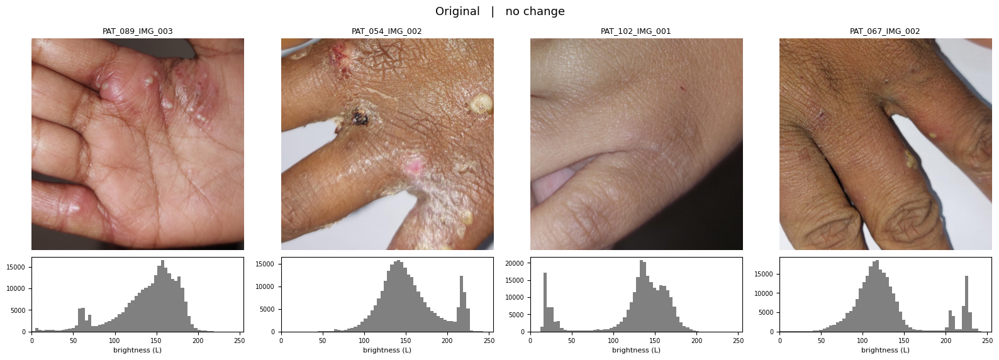

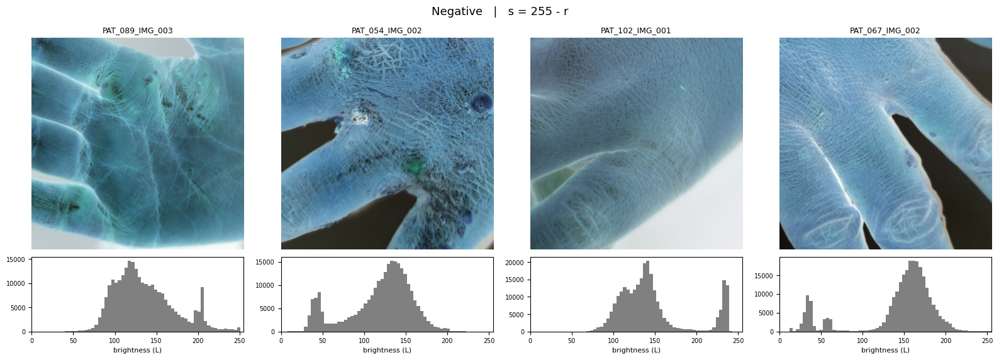

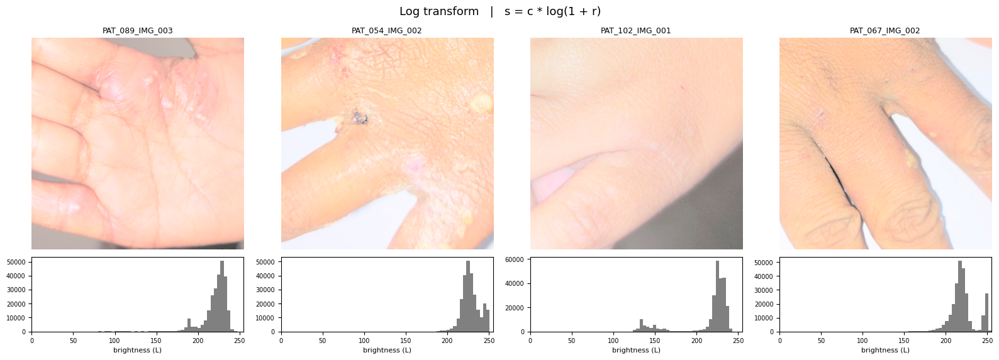

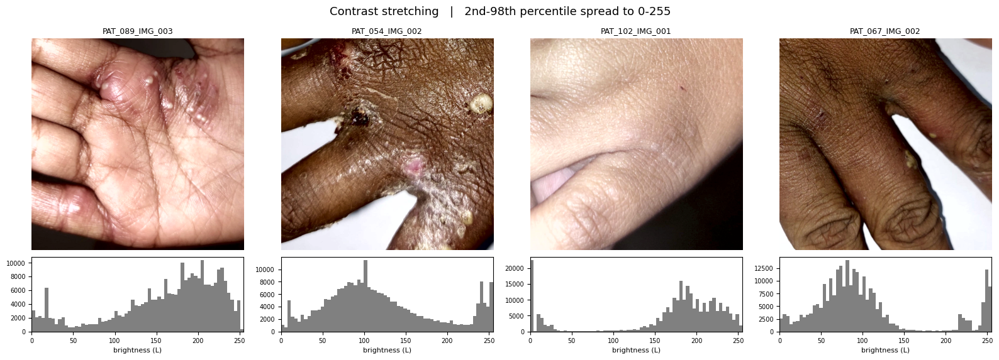

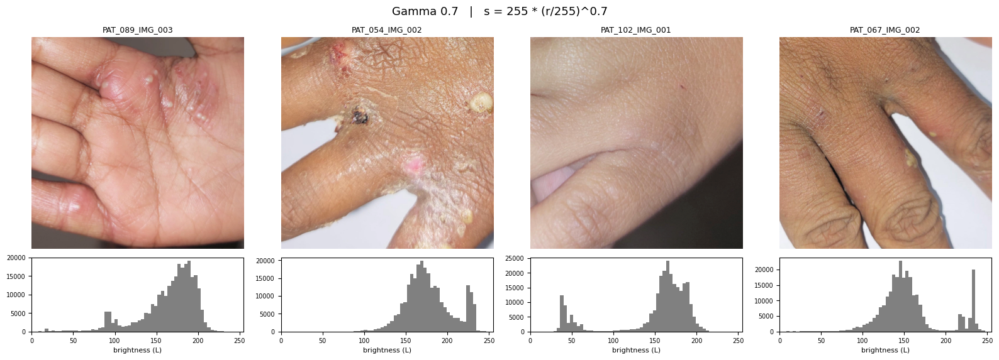

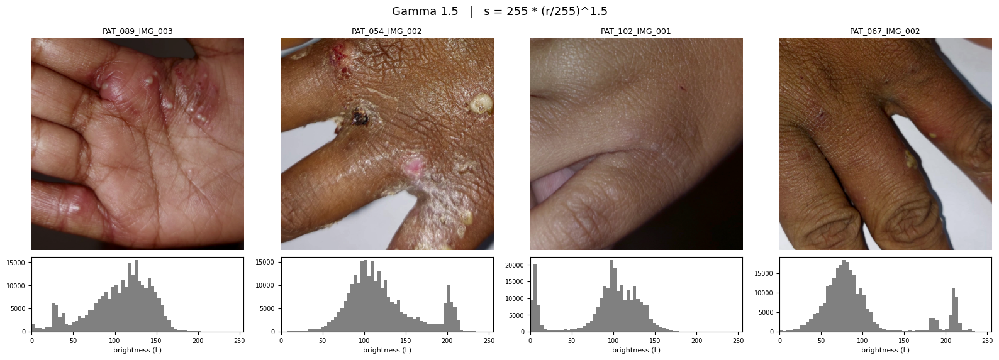

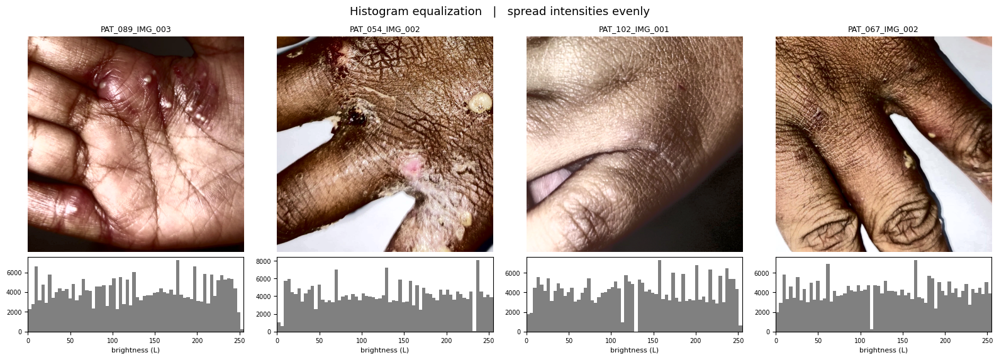




photo                   PAT_054_IMG_002  PAT_067_IMG_002  PAT_089_IMG_003  \
method                                                                      
Original                           34.5             44.0             37.6   
Negative                           39.0             48.0             36.0   
Log transform                      10.6             15.7             17.4   
Contrast stretching                65.9             66.5             64.6   
Gamma 0.7                          28.0             36.7             34.2   
Gamma 1.5                          41.2             50.6             38.2   
Histogram equalization             73.0             73.4             73.0   

photo                   PAT_102_IMG_001  
method                                   
Original                           47.8  
Negative                           42.0  
Log transform                      31.4  
Contrast stretching                73.8  
Gamma 0.7                          47.7  
Gamma 1.5

In [8]:
PHOTOS = ["PAT_089_IMG_003.jpg", "PAT_054_IMG_002.jpg",
          "PAT_102_IMG_001.jpg", "PAT_067_IMG_002.jpg"]
for p in PHOTOS:
    assert p in selected, f"{p} is not loaded: check USE_LABELS and Cell 1"
print("photos:", PHOTOS)

SHOW = ["original", "negative", "log", "stretch", "gamma_0.7", "gamma_1.5", "hist_eq"]
TITLES = {"original": "Original", "negative": "Negative", "log": "Log transform",
          "stretch": "Contrast stretching", "gamma_0.7": "Gamma 0.7",
          "gamma_1.5": "Gamma 1.5", "hist_eq": "Histogram equalization"}
FORMULAS = {"original": "no change", "negative": "s = 255 - r",
            "log": "s = c * log(1 + r)", "stretch": "2nd-98th percentile spread to 0-255",
            "gamma_0.7": "s = 255 * (r/255)^0.7", "gamma_1.5": "s = 255 * (r/255)^1.5",
            "hist_eq": "spread intensities evenly"}

rows = []
for m in SHOW:
    outs = [METHODS[m](selected[i]) for i in PHOTOS]

    fig, axes = plt.subplots(2, 4, figsize=(16, 5.8),
                             gridspec_kw={"height_ratios": [4, 1.3]})
    fig.suptitle(f"{TITLES[m]}   |   {FORMULAS[m]}", fontsize=13)
    for j, (pid, out) in enumerate(zip(PHOTOS, outs)):
        axes[0, j].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
        axes[0, j].set_title(pid.replace(".jpg", ""), fontsize=9)
        axes[0, j].axis("off")
        L = get_L(out)
        axes[1, j].hist(L.ravel(), bins=64, range=(0, 255), color="gray")
        axes[1, j].set_xlim(0, 255)
        axes[1, j].set_xlabel("brightness (L)", fontsize=8)
        axes[1, j].tick_params(labelsize=7)
        rows.append({"method": TITLES[m], "photo": pid.replace(".jpg", ""),
                     "mean_L": L.mean(), "std_L": L.std()})
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, f"intensity_{m}.png"), dpi=200, bbox_inches="tight")
    plt.show()
    print("\n\n")          # line gap before the next transformation

stats = pd.DataFrame(rows)
print(stats.pivot(index="method", columns="photo", values="std_L")
           .loc[[TITLES[m] for m in SHOW]].round(1))

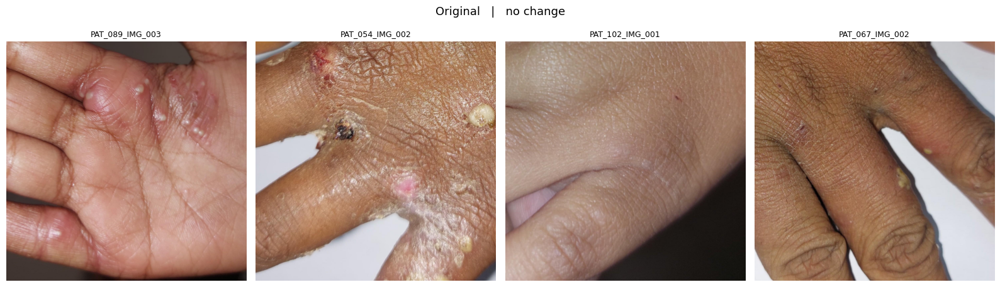

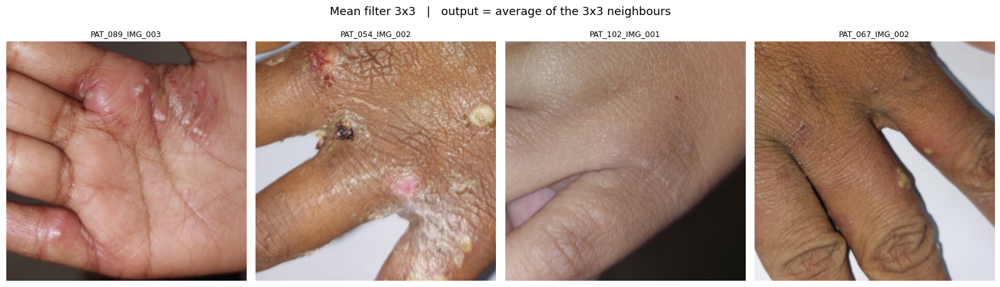

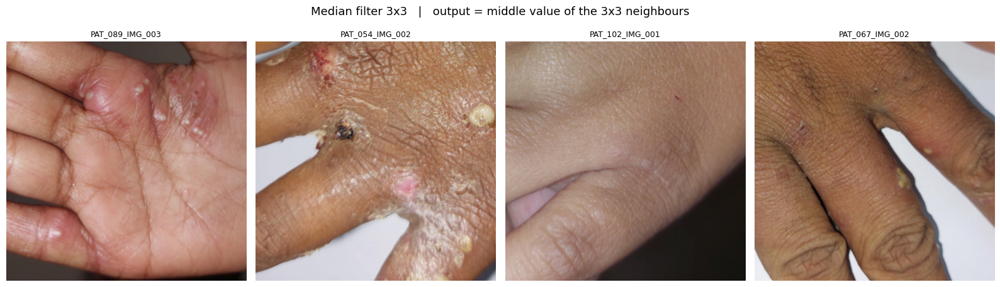

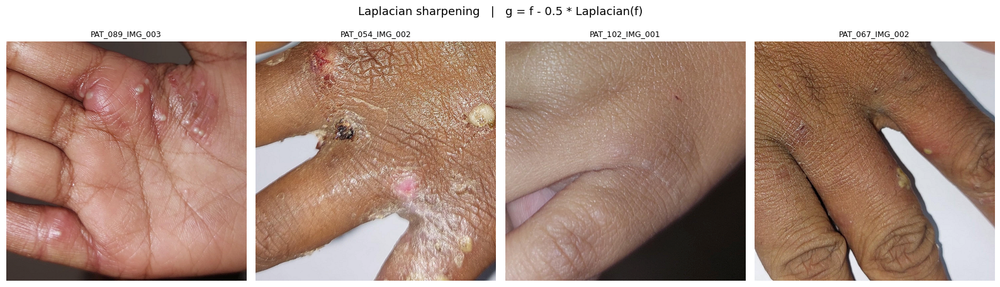

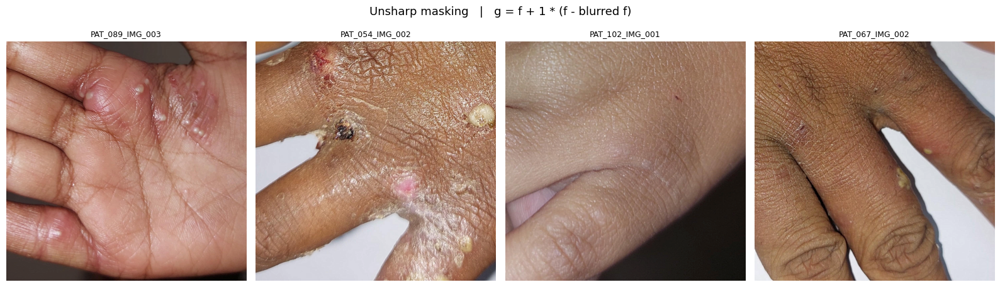

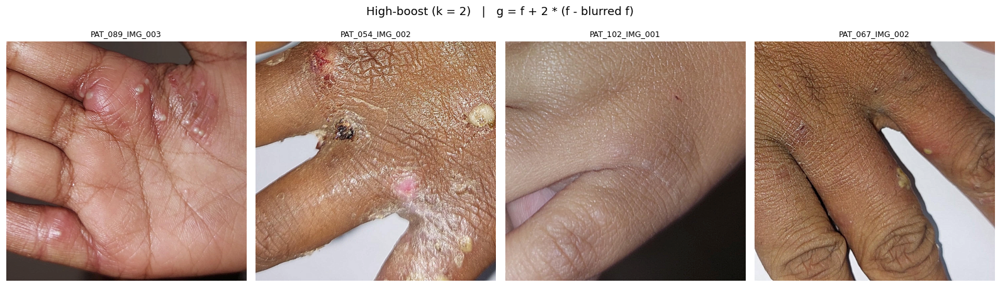

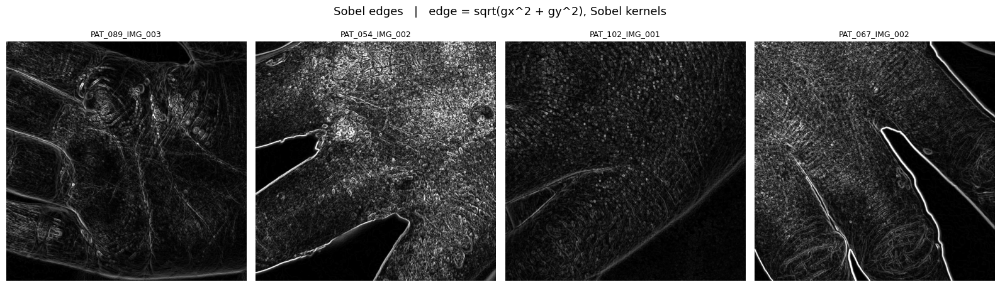

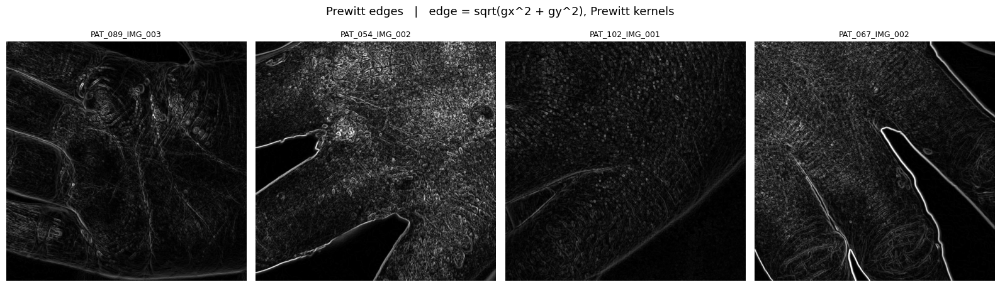

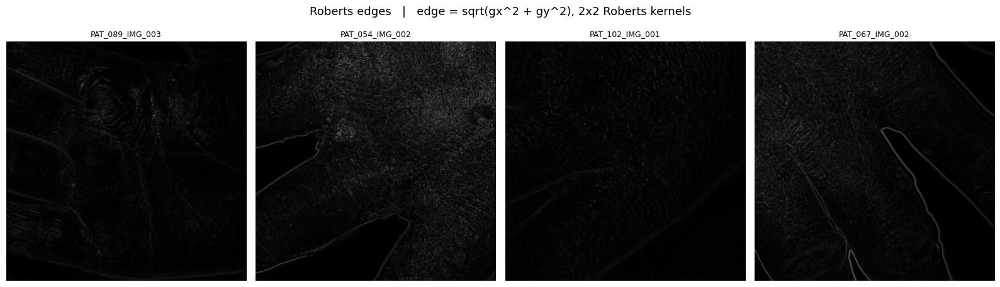




Fine-detail score (Laplacian variance): smoothing should drop, sharpening should rise
photo         PAT_054_IMG_002  PAT_067_IMG_002  PAT_089_IMG_003  \
method                                                            
original               1274.8            495.1             98.7   
mean_3x3                 62.8             30.7             10.6   
median_3x3              171.2             80.8             29.2   
laplacian             12966.6           5467.2            944.0   
unsharp                4595.2           1801.3            342.6   
highboost_k2           9383.1           3896.4            721.2   

photo         PAT_102_IMG_001  
method                         
original                 55.8  
mean_3x3                  9.3  
median_3x3               22.3  
laplacian               439.4  
unsharp                 184.2  
highboost_k2            384.4  

Mean edge-map brightness (stronger edges = higher), compare only these three
photo    PAT_054_IMG_002  PAT_067_IMG_00

In [9]:
PHOTOS = ["PAT_089_IMG_003.jpg", "PAT_054_IMG_002.jpg",
          "PAT_102_IMG_001.jpg", "PAT_067_IMG_002.jpg"]
for p in PHOTOS:
    assert p in selected, f"{p} is not loaded: check USE_LABELS and Cell 1"

SHOW = ["original", "mean_3x3", "median_3x3", "laplacian", "unsharp",
        "highboost_k2", "sobel", "prewitt", "roberts"]
TITLES = {"original": "Original", "mean_3x3": "Mean filter 3x3",
          "median_3x3": "Median filter 3x3", "laplacian": "Laplacian sharpening",
          "unsharp": "Unsharp masking", "highboost_k2": "High-boost (k = 2)",
          "sobel": "Sobel edges", "prewitt": "Prewitt edges", "roberts": "Roberts edges"}
RULES = {"original": "no change",
         "mean_3x3": "output = average of the 3x3 neighbours",
         "median_3x3": "output = middle value of the 3x3 neighbours",
         "laplacian": "g = f - 0.5 * Laplacian(f)",
         "unsharp": "g = f + 1 * (f - blurred f)",
         "highboost_k2": "g = f + 2 * (f - blurred f)",
         "sobel": "edge = sqrt(gx^2 + gy^2), Sobel kernels",
         "prewitt": "edge = sqrt(gx^2 + gy^2), Prewitt kernels",
         "roberts": "edge = sqrt(gx^2 + gy^2), 2x2 Roberts kernels"}

rows = []
for m in SHOW:
    outs = [METHODS[m](selected[i]) for i in PHOTOS]

    fig, axes = plt.subplots(1, 4, figsize=(16, 4.8))
    fig.suptitle(f"{TITLES[m]}   |   {RULES[m]}", fontsize=13)
    for ax, pid, out in zip(axes, PHOTOS, outs):
        ax.imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
        ax.set_title(pid.replace(".jpg", ""), fontsize=9)
        ax.axis("off")
        L = get_L(out)
        rows.append({"method": m, "photo": pid.replace(".jpg", ""),
                     "lap_var": cv2.Laplacian(L, cv2.CV_64F).var(),
                     "mean_L": L.mean()})
    plt.tight_layout()
    plt.savefig(os.path.join(FIG, f"spatial_{m}.png"), dpi=200, bbox_inches="tight")
    plt.show()
    print("\n\n")          # line gap before the next method

st = pd.DataFrame(rows)
enh = [m for m in SHOW if m not in ("sobel", "prewitt", "roberts")]
print("Fine-detail score (Laplacian variance): smoothing should drop, sharpening should rise")
print(st[st.method.isin(enh)].pivot(index="method", columns="photo",
      values="lap_var").loc[enh].round(1))
print("\nMean edge-map brightness (stronger edges = higher), compare only these three")
print(st[st.method.isin(["sobel", "prewitt", "roberts"])].pivot(
      index="method", columns="photo", values="mean_L").round(1))

In [10]:
import time
import numpy as np, pandas as pd
from IPython.display import display

PHOTOS = ["PAT_089_IMG_003.jpg", "PAT_054_IMG_002.jpg",
          "PAT_102_IMG_001.jpg", "PAT_067_IMG_002.jpg"]
for p in PHOTOS:
    assert p in selected, f"{p} is not loaded: check USE_LABELS and Cell 1"

L_FUNCS = {
    "stretch": stretch, "log": log_tf,
    "gamma_0.7": lambda L: gamma(L, 0.7), "gamma_1.5": lambda L: gamma(L, 1.5),
    "hist_eq": hist_eq,
    "mean_3x3": mean3, "median_3x3": median3,
    "laplacian": laplacian_sharp,
    "unsharp": lambda L: unsharp(L, 1.0, 1.0),
    "highboost_k2": lambda L: unsharp(L, 1.0, 2.0),
}
NK = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)   # Immerkaer noise kernel

def metrics(L):
    f = L.astype(np.float32)
    H, W = f.shape
    p = np.bincount(L.ravel(), minlength=256) / L.size
    p = p[p > 0]
    gx, gy = cv2.Sobel(f, cv2.CV_32F, 1, 0), cv2.Sobel(f, cv2.CV_32F, 0, 1)
    conv = cv2.filter2D(f, -1, NK)[1:-1, 1:-1]
    sigma = np.sqrt(np.pi / 2) * np.abs(conv).sum() / (6 * (H - 2) * (W - 2))
    return dict(contrast=f.std(), entropy=-(p * np.log2(p)).sum(),
                edge=np.hypot(gx, gy).mean(), noise=sigma)

METRIC_COLS = ["contrast_r", "entropy_r", "edge_r", "noise_r", "dnr_r", "time_ms"]
demo_winners = {}

def run_group(name, methods, ok, score, rule_text):
    recs = []
    for pid in PHOTOS:
        L = get_L(selected[pid])
        base = metrics(L)
        for m in methods:
            t = time.perf_counter(); out = L_FUNCS[m](L); ms = (time.perf_counter() - t) * 1000
            r = metrics(out)
            recs.append(dict(
                photo=pid.replace(".jpg", ""), method=m,
                contrast_r=r["contrast"] / base["contrast"],
                entropy_r=r["entropy"] / base["entropy"],
                edge_r=r["edge"] / base["edge"],
                noise_r=r["noise"] / base["noise"],
                dnr_r=(r["edge"] / r["noise"]) / (base["edge"] / base["noise"]),
                time_ms=ms))
    d = pd.DataFrame(recs)
    T = d.groupby("method")[METRIC_COLS].mean().loc[methods]
    T["pass"] = ok(T)
    rk = T[score].where(T["pass"]).rank(ascending=False, method="min")
    T["rank"] = rk.map(lambda v: "-" if pd.isna(v) else int(v))

    print(f"===== {name.upper()} =====")
    print("Rule:", rule_text)
    print("Table (mean ratio over the 4 photos; ratio = method / original of the same photo)")
    display(T.round(3))
    print(f"\n{score} for each photo (ranking metric):")
    display(d.pivot(index="method", columns="photo", values=score).loc[methods].round(3))

    ranked = T[T["pass"]].sort_values(score, ascending=False)
    if len(ranked):
        print("\nRanking (best first):",
              " > ".join(f"{m} ({v:.3f})" for m, v in ranked[score].items()))
        print("Winner:", ranked.index[0])
        demo_winners[name] = ranked.index[0]
    else:
        print("\nNo method passed the rule, so this group has no winner.")
        demo_winners[name] = None
    failed = list(T.index[~T["pass"]])
    print("Failed the rule:", failed if failed else "none")

# worked example with real numbers
L0 = get_L(selected[PHOTOS[0]])
a, b = metrics(L0), metrics(stretch(L0))
print(f"Worked example ({PHOTOS[0]}, contrast stretching): "
      f"contrast {a['contrast']:.2f} -> {b['contrast']:.2f}, "
      f"ratio = {b['contrast'] / a['contrast']:.3f}\n")

run_group("intensity",
          ["stretch", "log", "gamma_0.7", "gamma_1.5", "hist_eq"],
          ok=lambda T: (T.noise_r <= 1.5) & (T.entropy_r >= 0.95),
          score="contrast_r",
          rule_text="must have noise ratio <= 1.5 and entropy ratio >= 0.95; ranked by contrast gain")


Worked example (PAT_089_IMG_003.jpg, contrast stretching): contrast 37.62 -> 65.63, ratio = 1.745

===== INTENSITY =====
Rule: must have noise ratio <= 1.5 and entropy ratio >= 0.95; ranked by contrast gain
Table (mean ratio over the 4 photos; ratio = method / original of the same photo)


,contrast_r,entropy_r,edge_r,noise_r,dnr_r,time_ms,pass,rank
method,,,,,,,,
stretch,1.683,0.975,1.667,1.709,0.975,1.300,False,-
log,0.453,0.779,0.384,0.469,0.858,0.855,False,-
gamma_0.7,0.888,0.957,0.861,0.896,0.964,0.859,True,2
gamma_1.5,1.062,0.989,1.089,1.107,0.984,0.905,True,1
hist_eq,1.827,0.975,2.629,2.856,0.920,0.232,False,-



contrast_r for each photo (ranking metric):


photo,PAT_054_IMG_002,PAT_067_IMG_002,PAT_089_IMG_003,PAT_102_IMG_001
method,,,,
stretch,1.922,1.518,1.745,1.548
log,0.302,0.360,0.492,0.659
gamma_0.7,0.810,0.835,0.908,0.999
gamma_1.5,1.192,1.151,1.016,0.888
hist_eq,2.128,1.675,1.964,1.540



Ranking (best first): gamma_1.5 (1.062) > gamma_0.7 (0.888)
Winner: gamma_1.5
Failed the rule: ['stretch', 'log', 'hist_eq']


In [11]:
run_group("smoothing",
          ["mean_3x3", "median_3x3"],
          ok=lambda T: T.edge_r >= 0.7,
          score="dnr_r",
          rule_text="must keep edge ratio >= 0.7; ranked by detail-to-noise (DNR) gain")

===== SMOOTHING =====
Rule: must keep edge ratio >= 0.7; ranked by detail-to-noise (DNR) gain
Table (mean ratio over the 4 photos; ratio = method / original of the same photo)


,contrast_r,entropy_r,edge_r,noise_r,dnr_r,time_ms,pass,rank
method,,,,,,,,
mean_3x3,0.981,0.992,0.701,0.235,3.658,0.113,True,1
median_3x3,0.985,0.990,0.722,0.556,1.435,0.126,True,2



dnr_r for each photo (ranking metric):


photo,PAT_054_IMG_002,PAT_067_IMG_002,PAT_089_IMG_003,PAT_102_IMG_001
method,,,,
mean_3x3,5.440,4.718,2.579,1.895
median_3x3,1.851,1.766,1.229,0.895



Ranking (best first): mean_3x3 (3.658) > median_3x3 (1.435)
Winner: mean_3x3
Failed the rule: none


In [12]:
run_group("sharpening",
          ["laplacian", "unsharp", "highboost_k2"],
          ok=lambda T: T.noise_r <= 1.5,
          score="edge_r",
          rule_text="must have noise ratio <= 1.5; ranked by edge ratio")

print("\n===== WINNERS ON THESE 4 PHOTOS =====")
for g in ["smoothing", "intensity", "sharpening"]:
    print(f"{g:11s}: {demo_winners.get(g)}")
parts = [demo_winners[g] for g in ["smoothing", "intensity", "sharpening"] if demo_winners.get(g)]
print("Combination order (smoothing > intensity > sharpening):", " > ".join(parts))

===== SHARPENING =====
Rule: must have noise ratio <= 1.5; ranked by edge ratio
Table (mean ratio over the 4 photos; ratio = method / original of the same photo)


,contrast_r,entropy_r,edge_r,noise_r,dnr_r,time_ms,pass,rank
method,,,,,,,,
laplacian,1.084,1.033,1.671,3.973,0.421,0.342,False,-
unsharp,1.040,1.018,1.432,1.994,0.719,0.464,False,-
highboost_k2,1.090,1.035,1.878,2.948,0.638,0.461,False,-



edge_r for each photo (ranking metric):


photo,PAT_054_IMG_002,PAT_067_IMG_002,PAT_089_IMG_003,PAT_102_IMG_001
method,,,,
laplacian,1.833,1.732,1.532,1.587
unsharp,1.520,1.454,1.350,1.405
highboost_k2,2.031,1.928,1.724,1.830



No method passed the rule, so this group has no winner.
Failed the rule: ['laplacian', 'unsharp', 'highboost_k2']

===== WINNERS ON THESE 4 PHOTOS =====
smoothing  : mean_3x3
intensity  : gamma_1.5
sharpening : None
Combination order (smoothing > intensity > sharpening): mean_3x3 > gamma_1.5


In [13]:
import time
import numpy as np, pandas as pd
from IPython.display import display

L_FUNCS = {
    "stretch": stretch, "log": log_tf,
    "gamma_0.7": lambda L: gamma(L, 0.7), "gamma_1.5": lambda L: gamma(L, 1.5),
    "hist_eq": hist_eq,
    "mean_3x3": mean3, "median_3x3": median3,
    "laplacian": laplacian_sharp,
    "unsharp": lambda L: unsharp(L, 1.0, 1.0),
    "highboost_k2": lambda L: unsharp(L, 1.0, 2.0),
}
NK = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], np.float32)   # Immerkaer noise kernel

def metrics(L):
    f = L.astype(np.float32)
    H, W = f.shape
    p = np.bincount(L.ravel(), minlength=256) / L.size
    p = p[p > 0]
    gx, gy = cv2.Sobel(f, cv2.CV_32F, 1, 0), cv2.Sobel(f, cv2.CV_32F, 0, 1)
    conv = cv2.filter2D(f, -1, NK)[1:-1, 1:-1]
    sigma = np.sqrt(np.pi / 2) * np.abs(conv).sum() / (6 * (H - 2) * (W - 2))
    return dict(contrast=f.std(), entropy=-(p * np.log2(p)).sum(),
                edge=np.hypot(gx, gy).mean(), noise=sigma)

# ---------- compute every method on every image (ratio = method / original, same image) ----------
ids = list(selected)
recs = []
for n, i in enumerate(ids):
    L = get_L(selected[i]); base = metrics(L)
    for m, fn in L_FUNCS.items():
        t = time.perf_counter(); out = fn(L); ms = (time.perf_counter() - t) * 1000
        r = metrics(out)
        recs.append(dict(image=i, patient=i.split("_IMG")[0], method=m,
            contrast_r=r["contrast"] / base["contrast"],
            entropy_r=r["entropy"] / base["entropy"],
            edge_r=r["edge"] / base["edge"],
            noise_r=r["noise"] / base["noise"],
            dnr_r=(r["edge"] / r["noise"]) / (base["edge"] / base["noise"]),
            time_ms=ms))
    if (n + 1) % 100 == 0:
        print("processed", n + 1, "of", len(ids))
single = pd.DataFrame(recs)
single.to_csv(os.path.join(OUT, "single_metrics_all_images.csv"), index=False)

METRIC_COLS = ["contrast_r", "entropy_r", "edge_r", "noise_r", "dnr_r", "time_ms"]
pm = single.groupby(["patient", "method"])[METRIC_COLS].mean().reset_index()   # patient averages
print("images:", single.image.nunique(), "| patients:", pm.patient.nunique())

all_winners = {}

def run_group(name, methods, ok, score, rule_text):
    sub = pm[pm.method.isin(methods)]
    T = sub.groupby("method")[METRIC_COLS].mean().loc[methods]
    T["pass"] = ok(T)
    T["patients_pass_%"] = (sub.assign(p=ok(sub)).groupby("method")["p"].mean() * 100).loc[methods].round(1)
    rk = T[score].where(T["pass"]).rank(ascending=False, method="min")
    T["rank"] = rk.map(lambda v: "-" if pd.isna(v) else int(v))

    print(f"\n===== {name.upper()} (all {single.image.nunique()} images, "
          f"{pm.patient.nunique()} patients) =====")
    print("Rule:", rule_text)
    print("Table: mean of patient averages; ratio = method / original of the same image")
    display(T.round(3))
    print(f"\nSpread of {score} across patients:")
    display(sub.groupby("method")[score].agg(median="median", std="std", min="min", max="max")
               .loc[methods].round(3))

    ranked = T[T["pass"]].sort_values(score, ascending=False)
    if len(ranked):
        print("\nRanking (best first):",
              " > ".join(f"{m} ({v:.3f})" for m, v in ranked[score].items()))
        print("Winner:", ranked.index[0])
        all_winners[name] = ranked.index[0]
    else:
        print("\nNo method passed the rule, so this group has no winner.")
        all_winners[name] = None
    failed = list(T.index[~T["pass"]])
    print("Failed the rule:", failed if failed else "none")

run_group("intensity",
          ["stretch", "log", "gamma_0.7", "gamma_1.5", "hist_eq"],
          ok=lambda T: (T.noise_r <= 1.5) & (T.entropy_r >= 0.95),
          score="contrast_r",
          rule_text="noise ratio <= 1.5 and entropy ratio >= 0.95; ranked by contrast gain")

processed 100 of 406
processed 200 of 406
processed 300 of 406
processed 400 of 406
images: 406 | patients: 114

===== INTENSITY (all 406 images, 114 patients) =====
Rule: noise ratio <= 1.5 and entropy ratio >= 0.95; ranked by contrast gain
Table: mean of patient averages; ratio = method / original of the same image


,contrast_r,entropy_r,edge_r,noise_r,dnr_r,time_ms,pass,patients_pass_%,rank
method,,,,,,,,,
stretch,1.830,0.977,1.812,1.860,0.975,1.488,False,6.1,-
log,0.405,0.804,0.457,0.537,0.861,0.821,False,0.0,-
gamma_0.7,0.872,0.967,0.913,0.945,0.967,0.863,True,96.5,2
gamma_1.5,1.073,0.979,0.985,1.006,0.980,0.880,True,93.9,1
hist_eq,2.050,0.979,3.230,3.654,0.891,0.238,False,0.0,-



Spread of contrast_r across patients:


,median,std,min,max
method,,,,
stretch,1.750,0.431,1.417,5.465
log,0.394,0.069,0.302,0.758
gamma_0.7,0.867,0.034,0.814,1.003
gamma_1.5,1.078,0.057,0.891,1.183
hist_eq,1.959,0.561,1.340,6.327



Ranking (best first): gamma_1.5 (1.073) > gamma_0.7 (0.872)
Winner: gamma_1.5
Failed the rule: ['stretch', 'log', 'hist_eq']


In [14]:
run_group("smoothing",
          ["mean_3x3", "median_3x3"],
          ok=lambda T: T.edge_r >= 0.7,
          score="dnr_r",
          rule_text="edge ratio >= 0.7; ranked by detail-to-noise (DNR) gain")


===== SMOOTHING (all 406 images, 114 patients) =====
Rule: edge ratio >= 0.7; ranked by detail-to-noise (DNR) gain
Table: mean of patient averages; ratio = method / original of the same image


,contrast_r,entropy_r,edge_r,noise_r,dnr_r,time_ms,pass,patients_pass_%,rank
method,,,,,,,,,
mean_3x3,0.983,0.986,0.661,0.296,2.723,0.130,False,26.3,-
median_3x3,0.988,0.985,0.690,0.716,1.085,0.133,False,36.8,-



Spread of dnr_r across patients:


,median,std,min,max
method,,,,
mean_3x3,2.647,0.875,0.710,5.100
median_3x3,1.039,0.293,0.593,1.889



No method passed the rule, so this group has no winner.
Failed the rule: ['mean_3x3', 'median_3x3']


In [15]:
run_group("sharpening",
          ["laplacian", "unsharp", "highboost_k2"],
          ok=lambda T: T.noise_r <= 1.5,
          score="edge_r",
          rule_text="noise ratio <= 1.5; ranked by edge ratio")

print("\n===== WINNERS ON ALL 406 IMAGES =====")
for g in ["smoothing", "intensity", "sharpening"]:
    print(f"{g:11s}: {all_winners.get(g)}")
parts = [all_winners[g] for g in ["smoothing", "intensity", "sharpening"] if all_winners.get(g)]
print("Combination order (smoothing > intensity > sharpening):", " > ".join(parts))


===== SHARPENING (all 406 images, 114 patients) =====
Rule: noise ratio <= 1.5; ranked by edge ratio
Table: mean of patient averages; ratio = method / original of the same image


,contrast_r,entropy_r,edge_r,noise_r,dnr_r,time_ms,pass,patients_pass_%,rank
method,,,,,,,,,
laplacian,1.066,1.043,1.746,3.794,0.462,0.349,False,0.0,-
unsharp,1.035,1.026,1.485,1.994,0.746,0.479,False,0.0,-
highboost_k2,1.082,1.050,1.985,2.943,0.676,0.484,False,0.0,-



Spread of edge_r across patients:


,median,std,min,max
method,,,,
laplacian,1.770,0.124,1.388,1.971
unsharp,1.498,0.063,1.285,1.592
highboost_k2,2.012,0.127,1.582,2.200



No method passed the rule, so this group has no winner.
Failed the rule: ['laplacian', 'unsharp', 'highboost_k2']

===== WINNERS ON ALL 406 IMAGES =====
smoothing  : None
intensity  : gamma_1.5
sharpening : None
Combination order (smoothing > intensity > sharpening): gamma_1.5


## Extra 1: does the combination order smoothing > intensity > sharpening actually win?
Your notebook assumes this order. This cell applies every order of the three group winners (and each winner alone) to all selected images, with the same rule as the sharpening group (noise ratio <= 1.5, entropy ratio >= 0.95) and ranks by detail-to-noise (DNR) gain.

In [16]:
import itertools
FORCE_CHAIN = None   # e.g. ["median_3x3", "gamma_1.5", "unsharp"] to test orders even when a group has no winner (say so in the report)
GROUPS3 = ["smoothing", "intensity", "sharpening"]
chain = FORCE_CHAIN or [all_winners[g] for g in GROUPS3 if all_winners.get(g)]
print("methods tested:", chain)

if len(chain) < 2:
    print("Order test skipped: needs at least 2 methods. Groups without a winner:",
          [g for g in GROUPS3 if not all_winners.get(g)], "| set FORCE_CHAIN to test anyway.")
else:
    fn_of = dict(L_FUNCS)
    def apply_chain(L, names):
        for n in names: L = fn_of[n](L)
        return L

    cands = list(itertools.permutations(chain)) + [(m,) for m in chain]
    recs = []
    for n, i in enumerate(sel_meta.Image_id):
        L = get_L(selected[i]); base = metrics(L)
        for o in cands:
            r = metrics(apply_chain(L, o))
            recs.append(dict(patient=sel_meta.patient[n], order=" > ".join(o), contrast_r=r["contrast"] / base["contrast"],
                entropy_r=r["entropy"] / base["entropy"], edge_r=r["edge"] / base["edge"], noise_r=r["noise"] / base["noise"],
                dnr_r=(r["edge"] / r["noise"]) / (base["edge"] / base["noise"])))
    co = pd.DataFrame(recs).groupby(["patient", "order"]).mean().reset_index()
    CT = co.groupby("order")[["contrast_r", "entropy_r", "edge_r", "noise_r", "dnr_r"]].mean()
    CT["pass"] = (CT.noise_r <= 1.5) & (CT.entropy_r >= 0.95)
    display(CT.sort_values("dnr_r", ascending=False).round(3))
    ok = CT[CT["pass"]].sort_values("dnr_r", ascending=False)
    listed = " > ".join(chain)
    if len(ok):
        print("Best passing order by DNR gain:", ok.index[0])
        print(f"Same as the assumed order ({listed}):", ok.index[0] == listed)
    else:
        print("No order passed the rule.")

methods tested: ['gamma_1.5']
Order test skipped: needs at least 2 methods. Groups without a winner: ['smoothing', 'sharpening'] | set FORCE_CHAIN to test anyway.


## Extra 2: how much do the winners depend on the metric?
Contrast (std of L) rises almost by definition under contrast stretching and histogram equalization, and DNR favours smoothing. This table ranks the methods in each group under every metric (1 = best; for noise, lower is better). If the ranks disagree, the winner is a property of the metric, not proof of better diagnostic value.

In [17]:
groups_ = {"intensity": ["stretch", "log", "gamma_0.7", "gamma_1.5", "hist_eq"],
           "smoothing": ["mean_3x3", "median_3x3"], "sharpening": ["laplacian", "unsharp", "highboost_k2"]}
for g, ms in groups_.items():
    T = pm[pm.method.isin(ms)].groupby("method")[["contrast_r", "entropy_r", "edge_r", "noise_r", "dnr_r"]].mean().loc[ms]
    R = T.rank(ascending=False, method="min").astype(int)
    R["noise_r"] = T["noise_r"].rank(ascending=True, method="min").astype(int)
    print(f"\n===== {g.upper()}: rank per metric (1 = best) =====")
    display(R)


===== INTENSITY: rank per metric (1 = best) =====


,contrast_r,entropy_r,edge_r,noise_r,dnr_r
method,,,,,
stretch,2,3,2,4,2
log,5,5,5,1,5
gamma_0.7,4,4,4,2,3
gamma_1.5,3,2,3,3,1
hist_eq,1,1,1,5,4



===== SMOOTHING: rank per metric (1 = best) =====


,contrast_r,entropy_r,edge_r,noise_r,dnr_r
method,,,,,
mean_3x3,2,1,2,1,1
median_3x3,1,2,1,2,2



===== SHARPENING: rank per metric (1 = best) =====


,contrast_r,entropy_r,edge_r,noise_r,dnr_r
method,,,,,
laplacian,2,2,2,3,3
unsharp,3,3,3,1,1
highboost_k2,1,1,1,2,2


## Limitations to state in the report
- Winners are defined by image-quality metrics (contrast, entropy, edge, noise, DNR), not by classification accuracy. Whether a method helps a CNN is future work.
- Cropping (`RESIZE_MODE = "crop"`) removes image borders on non-square photos; use `"pad"` if lesions sit near the edge. Compare both once.
- The combination order is tested only among the three group winners, using the metrics above.
- Results come from one dataset (Comilla). Repeat on SkinDisNet before saying the same method wins everywhere.